In [27]:
import tensorflow as tf
from tensorflow.keras import models,layers
import matplotlib.pyplot as plt



In [2]:
import warnings
warnings.filterwarnings('ignore')

In [3]:
IMAGE_SIZE=256
BATCH_SIZE=32
CHANNELS=3

In [4]:
dataSet = tf.keras.preprocessing.image_dataset_from_directory(
    "/kaggle/input/dataset/Dataset",                                              
    shuffle=True,
    image_size = (IMAGE_SIZE,IMAGE_SIZE),
    batch_size  =BATCH_SIZE,
    )

Found 2152 files belonging to 3 classes.


I0000 00:00:1757301177.729430      36 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1757301177.730059      36 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [5]:
className = dataSet.class_names

In [6]:
className

['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']

In [7]:
for imageBatch,labelsBatch in dataSet.take(1):
    print(imageBatch.shape)
    print(labelsBatch.numpy())
    

(32, 256, 256, 3)
[1 0 2 0 2 1 1 1 0 0 1 1 1 1 0 0 0 1 0 0 0 0 1 0 0 0 2 0 1 0 2 1]


# Visualize some of the images form out datatset

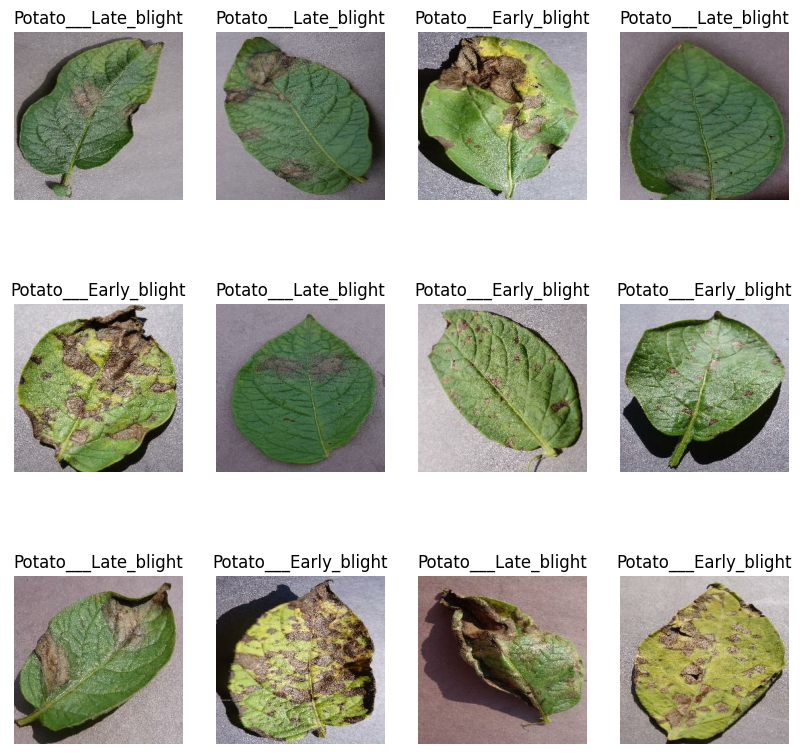

In [8]:
plt.figure(figsize=(10,10))
for imageBatch,labelBatch in dataSet.take(1):
    for i in range(12):
        ax=plt.subplot(3,4,i+1)
        plt.imshow(imageBatch[i].numpy().astype("uint8"))
        plt.title(className[labelBatch[i]])
        plt.axis('off')

# Split the dataset
1) Training
2) validation
3) Testing


In [9]:
len(dataSet)

68

In [10]:
trainSize = 0.8
len(dataSet)*trainSize

54.400000000000006

In [11]:
trainDS = dataSet.take(54)
len(trainDS)

54

In [12]:
testDS = dataSet.skip(54)
len(testDS)

14

In [13]:
valSize=0.1
len(dataSet)*valSize

6.800000000000001

In [14]:
valDS = testDS.take(6)
len(valDS)

6

In [15]:
testDS = testDS.skip(6)
len(testDS)

8

In [16]:
def getDataSetParatitionsTF(ds,
                            train_spLit=0.8,
                            test_split=0.1,
                            val_split=0.1,
                            shuffle=True,
                           shuffle_size=10000):
    assert train_spLit+test_split+val_split == 1
    dsSize=len(ds)
    if shuffle:
        ds=ds.shuffle(shuffle_size,seed=12)
    trainSize=int(train_spLit*dsSize)
    valSize=int(val_split*dsSize)

    trainDS = ds.take(trainSize)
    valDS = ds.skip(trainSize).take(valSize)
    testDS = ds.skip(trainSize).skip(valSize)
    
    return trainDS,valDS,testDS

In [17]:
trainDS,valDS,testDS = getDataSetParatitionsTF(dataSet)

In [18]:
print(len(trainDS))
print(len(valDS))
print(len(testDS))

54
6
8


# Cache , Shuffle and Prefetch the dataset

In [19]:
trainDS = trainDS.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
testDS = testDS.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
valDS = valDS.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)

# Data Resizing and Normalization

In [20]:
reSize_and_reScale = tf.keras.Sequential(
    [
        layers.Resizing(IMAGE_SIZE,IMAGE_SIZE),
        layers.Rescaling(1.0/255)
    ]
)

# Data Augmentation

In [21]:
dataAugmentation = tf.keras.Sequential([
    layers.RandomFlip(mode='Horizontal_and_vertical'),
    layers.RandomRotation(factor=0.2)
])

In [22]:
trainDS=trainDS.map(
    lambda x,y : (dataAugmentation(x,training=True),y)).prefetch(buffer_size=tf.data.AUTOTUNE)

# Model Architecture

In [23]:
inputShape = (BATCH_SIZE,IMAGE_SIZE,IMAGE_SIZE,CHANNELS)
nClasses = 3

model = models.Sequential(
    [
        reSize_and_reScale,
        layers.Conv2D(32,
                      kernel_size=(3,3),
                      activation='relu',
                     input_shape = inputShape),
        layers.MaxPooling2D(2,2),
        


        layers.Conv2D(64,
                      kernel_size=(3,3),
                      activation='relu',),
        layers.MaxPooling2D(2,2),


        layers.Conv2D(64,
                      kernel_size=(3,3),
                      activation='relu',),
        layers.MaxPooling2D(2,2),



        layers.Conv2D(64,
                      kernel_size=(3,3),
                      activation='relu',),
        layers.MaxPooling2D(2,2),



        layers.Conv2D(64,
                      kernel_size=(3,3),
                      activation='relu',),
        layers.MaxPooling2D(2,2),

        

        
        layers.Conv2D(64,
                      kernel_size=(3,3),
                      activation='relu',),
        layers.MaxPooling2D(2,2),


        layers.Flatten(),
        layers.Dense(64,activation='relu'),
        layers.Dense(nClasses,activation='softmax'),
        
    ]
)

model.build(input_shape=inputShape)

In [24]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (32, 256, 256, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (32, 254, 254, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (32, 127, 127, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (32, 125, 125, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (32, 62, 62, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (32, 60, 60, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (32, 30, 30, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (32, 28, 28, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (32, 14, 14, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (32, 12, 12, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (32, 6, 6, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (32, 4, 4, 64)         │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (32, 2, 2, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (32, 256)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (32, 64)               │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (32, 3)                │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 183,747 (717.76 KB)

 Trainable params: 183,747 (717.76 KB)

 Non-trainable params: 0 (0.00 B)

In [25]:
model.compile(
    optimizer = 'adam',
    loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics = ['accuracy']
)

In [28]:
history01 = model.fit(
    trainDS,
    epochs = 20,
    batch_size=BATCH_SIZE,
    verbose=1,
    validation_data  =valDS
    
)

Epoch 1/20


I0000 00:00:1757301205.721106     104 service.cc:148] XLA service 0x7eec4810ebb0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1757301205.721894     104 service.cc:156]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1757301205.721915     104 service.cc:156]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1757301206.099059     104 cuda_dnn.cc:529] Loaded cuDNN version 90300


 2/54 ━━━━━━━━━━━━━━━━━━━━ 2s 55ms/step - accuracy: 0.4688 - loss: 1.0831  

I0000 00:00:1757301211.658128     104 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


54/54 ━━━━━━━━━━━━━━━━━━━━ 27s 261ms/step - accuracy: 0.4732 - loss: 0.9163 - val_accuracy: 0.5365 - val_loss: 0.8281
Epoch 2/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 10s 191ms/step - accuracy: 0.6679 - loss: 0.7078 - val_accuracy: 0.8594 - val_loss: 0.4380
Epoch 3/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 11s 193ms/step - accuracy: 0.8398 - loss: 0.3710 - val_accuracy: 0.7865 - val_loss: 0.4650
Epoch 4/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 10s 189ms/step - accuracy: 0.8772 - loss: 0.3111 - val_accuracy: 0.9115 - val_loss: 0.2234
Epoch 5/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 10s 189ms/step - accuracy: 0.9016 - loss: 0.2405 - val_accuracy: 0.9219 - val_loss: 0.2498
Epoch 6/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 10s 191ms/step - accuracy: 0.9103 - loss: 0.2523 - val_accuracy: 0.9427 - val_loss: 0.1399
Epoch 7/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 10s 190ms/step - accuracy: 0.9423 - loss: 0.1649 - val_accuracy: 0.9635 - val_loss: 0.1093
Epoch 8/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 10s 188ms/step - accuracy: 0.9168 - loss: 0.1909 - val_accuracy: 0.953

In [29]:
scores = model.evaluate(testDS)

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.9608 - loss: 0.0973


In [30]:
scores

[0.094048410654068, 0.96484375]

In [31]:
history01.params

{'verbose': 1, 'epochs': 20, 'steps': 54}

In [33]:
history01.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

In [35]:
type(history01.history['loss'])

list

In [36]:
len(history01.history['loss'])

20

In [37]:
acc  =history01.history['accuracy']
valAcc  =history01.history['val_accuracy']
loss  =history01.history['loss']
valLoss  =history01.history['val_loss']

In [38]:
acc

[0.4930555522441864,
 0.7540509104728699,
 0.8570601940155029,
 0.8807870149612427,
 0.9212962985038757,
 0.9241898059844971,
 0.9415509104728699,
 0.9288194179534912,
 0.9473379850387573,
 0.9537037014961243,
 0.9305555820465088,
 0.9542824029922485,
 0.9560185074806213,
 0.9519675970077515,
 0.9496527910232544,
 0.9606481194496155,
 0.9612268805503845,
 0.9681712985038757,
 0.9548611044883728,
 0.9606481194496155]

In [39]:
valAcc

[0.5364583134651184,
 0.859375,
 0.7864583134651184,
 0.9114583134651184,
 0.921875,
 0.9427083134651184,
 0.9635416865348816,
 0.953125,
 0.9427083134651184,
 0.9791666865348816,
 0.96875,
 0.9739583134651184,
 0.921875,
 0.96875,
 0.9583333134651184,
 0.9479166865348816,
 0.953125,
 0.9375,
 0.96875,
 0.9635416865348816]

# Visualize loss and accuracy in graph

Text(0.5, 1.0, 'Traning & Validation Loss')

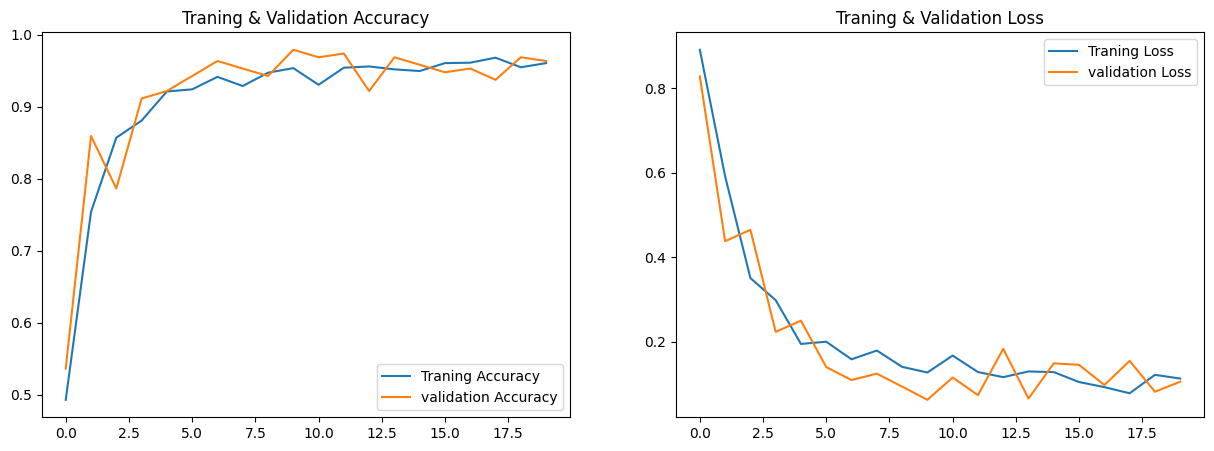

In [43]:
plt.figure(figsize=(15,5))
plt.subplot(1,2,1)
plt.plot(range(20),acc,label = 'Traning Accuracy')
plt.plot(range(20),valAcc,label = 'validation Accuracy')
plt.legend(loc = 'lower right')
plt.title('Traning & Validation Accuracy')


plt.subplot(1,2,2)
plt.plot(range(20),loss,label = 'Traning Loss')
plt.plot(range(20),valLoss,label = 'validation Loss')
plt.legend(loc = 'upper right')
plt.title('Traning & Validation Loss')


First image to predict
actual label : Potato___Late_blight
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
predicted label : Potato___Late_blight


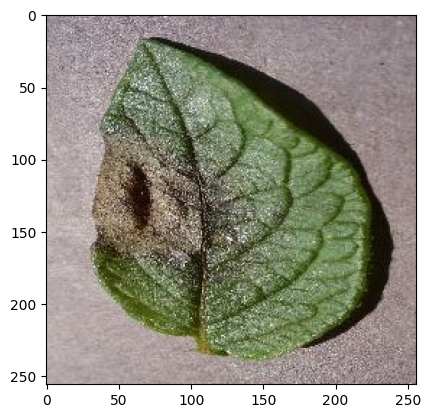

In [50]:
import numpy as np
for imageBatch,labelBatch in testDS.take(1):
    firstImg = imageBatch[0].numpy().astype('uint8')
    firstLabel = labelBatch[0].numpy()

    print("First image to predict")
    plt.imshow(firstImg)
    print("actual label :",className[firstLabel])
    batchPrediction = model.predict(imageBatch)
    print('predicted label :',className[np.argmax(batchPrediction[0])])

In [55]:
def predict(model,img):
    imgArr = tf.keras.preprocessing.image.img_to_array(img.numpy())
    imgArr = tf.expand_dims(imgArr,0)

    prediction = model.predict(imgArr)

    predictedClass = className[np.argmax(prediction[0])]
    confidence = round(100*(np.argmax(prediction[0])),2)
    return predictedClass,confidence

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


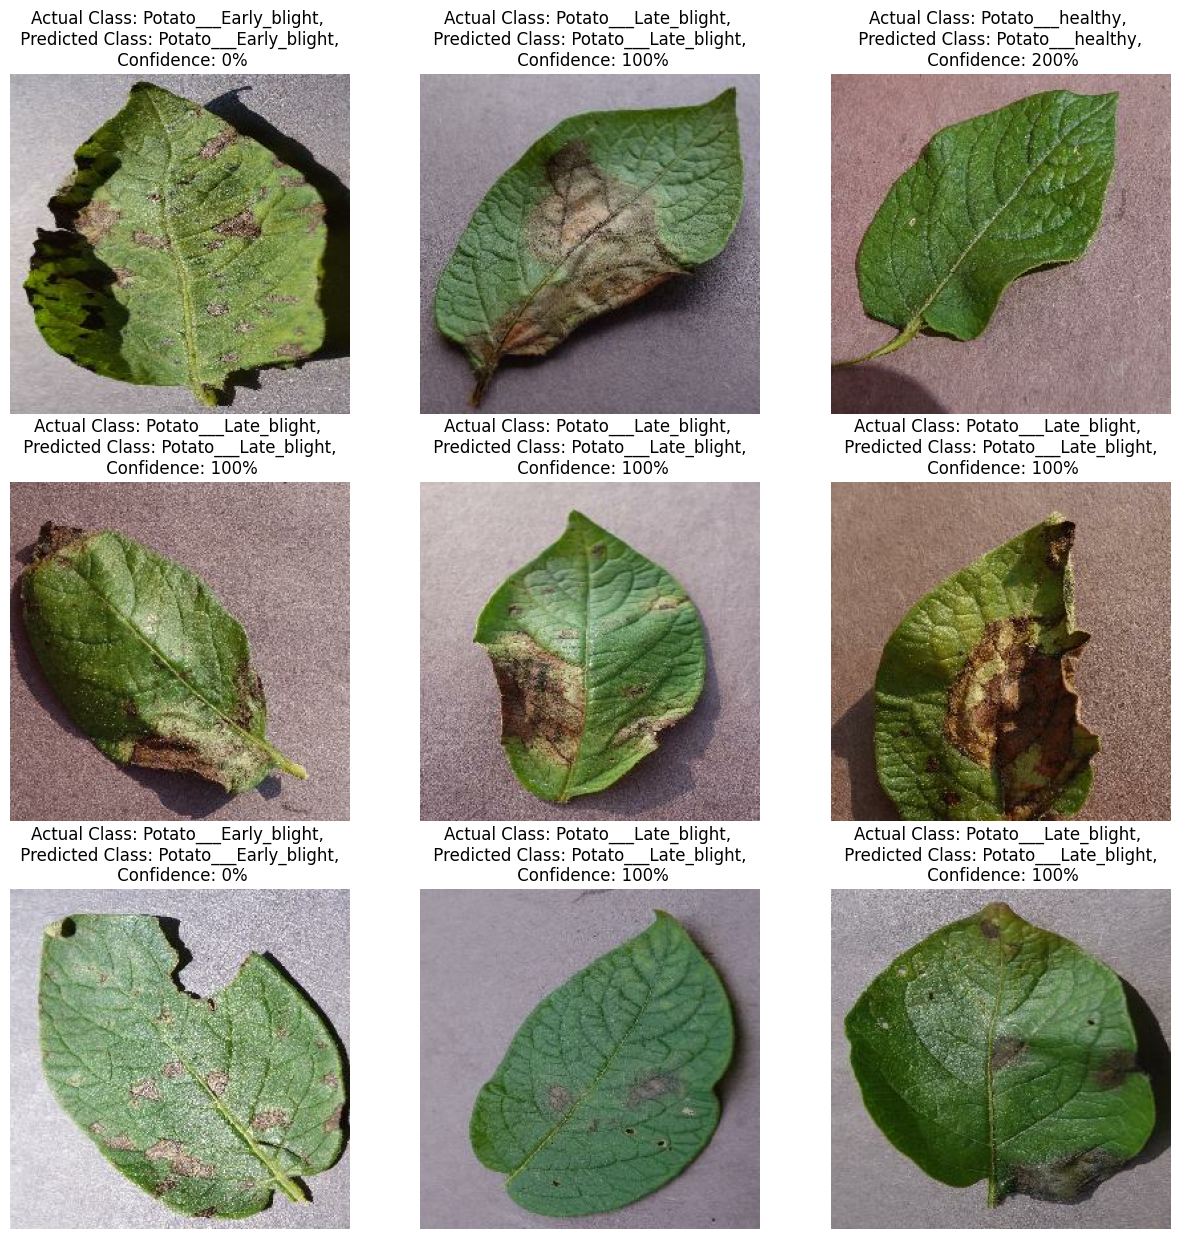

In [56]:
plt.figure(figsize=(15,15))
for image,label in testDS.take(1):
    for i in range(9): 
        ax = plt.subplot(3,3,i+1)
        plt.imshow(image[i].numpy().astype('uint8'))
        predictedClass,confidence = predict(model,image[i])
        actualClass  = className[label[i]]
        plt.title(f"Actual Class: {actualClass}, \n Predicted Class: {predictedClass}, \n Confidence: {confidence}%")
        plt.axis('off')
